In [1]:
# Integrating the financial and operations preprocessing pipelines
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

### Financial preprocessing pipeline

In [2]:
# Define financial column groups

MINOR_OUTLIER_COLS = [
    "Revenue Per Share (Yuan ¥)",
    "Net Value Growth Rate",
    "Current Ratio",
    "Quick Ratio",
    "Total debt/Total net worth",
    "Accounts Receivable Turnover",
    "Average Collection Days",
    "Revenue per person",
    "Allocation rate per person",
    "Quick Assets/Current Liability",
    "Cash/Current Liability",
    "Inventory/Current Liability",
    "Long-term Liability to Current Assets",
    "Fixed Assets to Assets",
    "Total assets to GNP price"
]

BORDERLINE_COL = "Interest-bearing debt interest rate"

SEVERE_COLS = [
    "Total Asset Growth Rate",
    "Cash Turnover Rate",
    "Research and development expense rate",
    "Inventory Turnover Rate (times)",
    "Quick Asset Turnover Rate",
    "Operating Expense Rate",
    "Current Asset Turnover Rate",
    "Fixed Assets Turnover Frequency"
]

COL_TO_DROP_FROM_PAIR = "Current Liability to Equity"

cols_to_cap = MINOR_OUTLIER_COLS + [BORDERLINE_COL]

In [3]:
# Reusable financial preprocessing functions

def verify_exact_duplicate(df, keep_col, drop_col, atol=1e-12):
    """Confirm two columns are exact duplicates before dropping one automatically."""
    keep_values = pd.to_numeric(df[keep_col], errors="coerce").to_numpy()
    drop_values = pd.to_numeric(df[drop_col], errors="coerce").to_numpy()
    identical = np.allclose(
        keep_values,
        drop_values,
        equal_nan=True,
        atol=atol,
        rtol=0,
    )
    max_abs_diff = np.nanmax(np.abs(keep_values - drop_values))
    if not identical:
        raise ValueError(
            f"{keep_col!r} and {drop_col!r} are not exact duplicates; "
            "do not drop one automatically."
        )
    return float(max_abs_diff)


def fit_cap_thresholds(df, columns, upper_quantile=0.99):
    """Learn capping thresholds from the training data."""
    thresholds = {}

    for col in columns:
        thresholds[col] = df[col].quantile(upper_quantile)

    return thresholds


def apply_caps(df, thresholds):
    """Apply the training capping thresholds to a dataframe."""
    df = df.copy()

    for col, cap_value in thresholds.items():
        df[col] = df[col].clip(upper=cap_value)

    return df


def drop_unreliable_columns(df, severe_cols, col_to_drop_from_pair):
    """Drop severely corrupted and multicollinear features."""
    cols_to_drop = severe_cols + [col_to_drop_from_pair]

    return df.drop(
        columns=cols_to_drop,
        errors="ignore"
    )


ROA_COLS = [
    "ROA(A) before interest and % after tax",
    "ROA(B) before interest and depreciation after tax",
    "ROA(C) before interest and depreciation before interest",
]


def engineer_financial_features(df):
    """Create two new financial-risk features.

    Liquidity_Buffer was removed: it is an exact linear transformation of
    Net worth/Assets and Debt ratio % (both already in the feature set) and
    adds no new information. The three ROA variants are replaced by a
    single Profitability_Composite instead of being kept alongside it.
    """
    df = df.copy()

    df["Profitability_Composite"] = df[ROA_COLS].mean(axis=1)
    df = df.drop(columns=ROA_COLS)

    df["Compounding_Leverage_Risk"] = (
        df["Current Liability to Assets"] *
        df["Borrowing dependency"]
    )

    return df


def clean_financial_layer(
    df,
    cap_thresholds=None,
    is_training=False
):
    """Run the complete financial cleaning process."""
    df = df.copy()

    if is_training:
        cap_thresholds = fit_cap_thresholds(
            df,
            cols_to_cap,
            upper_quantile=0.99
        )

    if cap_thresholds is None:
        raise ValueError(
            "Training cap thresholds are required for test data."
        )

    df = apply_caps(df, cap_thresholds)

    max_duplicate_diff = verify_exact_duplicate(
        df,
        keep_col="Current Liabilities/Equity",
        drop_col=COL_TO_DROP_FROM_PAIR,
    )
    print("Verified exact duplicate pair; max absolute difference:", max_duplicate_diff)

    df = drop_unreliable_columns(
        df,
        SEVERE_COLS,
        COL_TO_DROP_FROM_PAIR
    )

    df = engineer_financial_features(df)

    if is_training:
        return df, cap_thresholds

    return df


In [4]:
import kagglehub
import os

path = kagglehub.dataset_download(
    "fedesoriano/company-bankruptcy-prediction"
)

print("Downloaded to:", path)
print(os.listdir(path))

C:\Users\<user>\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Downloaded to: C:\Users\<user>\.cache\kagglehub\datasets\fedesoriano\company-bankruptcy-prediction\versions\2
['data.csv']


In [5]:
financial_file = os.path.join(path, "data.csv")

financial_df = pd.read_csv(financial_file)
financial_df.columns = financial_df.columns.str.strip()

print("Financial dataset shape:", financial_df.shape)

Financial dataset shape: (6819, 96)


### Leakage-safe preprocessing methodology

Both datasets are split into stratified training and test sets before any data dependent preprocessing is fitted.

In [6]:
#Split Datasets
financial_train_raw, financial_test_raw = train_test_split(
    financial_df,
    test_size=0.20,
    stratify=financial_df["Bankrupt?"],
    random_state=42
)

In [7]:
financial_train_clean, financial_cap_thresholds = clean_financial_layer(
    financial_train_raw,
    is_training=True
)

financial_test_clean = clean_financial_layer(
    financial_test_raw,
    cap_thresholds=financial_cap_thresholds,
    is_training=False
)

print("Train:", financial_train_clean.shape)
print("Test:", financial_test_clean.shape)

Verified exact duplicate pair; max absolute difference: 0.0
Verified exact duplicate pair; max absolute difference: 0.0
Train: (5455, 86)
Test: (1364, 86)


In [8]:
X_financial_train = financial_train_clean.drop(columns=["Bankrupt?"])
y_financial_train = financial_train_clean["Bankrupt?"]

X_financial_test = financial_test_clean.drop(columns=["Bankrupt?"])
y_financial_test = financial_test_clean["Bankrupt?"]

In [9]:
financial_scaler = StandardScaler()

X_financial_train_scaled = pd.DataFrame(
    financial_scaler.fit_transform(X_financial_train),
    columns=X_financial_train.columns,
    index=X_financial_train.index
)

X_financial_test_scaled = pd.DataFrame(
    financial_scaler.transform(X_financial_test),
    columns=X_financial_test.columns,
    index=X_financial_test.index
)

assert X_financial_train_scaled.isna().sum().sum() == 0
assert X_financial_test_scaled.isna().sum().sum() == 0
assert np.isfinite(X_financial_train_scaled.to_numpy()).all()
assert np.isfinite(X_financial_test_scaled.to_numpy()).all()

print("Financial train:", X_financial_train_scaled.shape)
print("Financial test:", X_financial_test_scaled.shape)
print("Financial pipeline checks passed.")


Financial train: (5455, 85)
Financial test: (1364, 85)
Financial pipeline checks passed.


In [10]:
import joblib

X_financial_train_scaled.to_csv("financial_X_train_processed.csv", index=False)
X_financial_test_scaled.to_csv("financial_X_test_processed.csv", index=False)
y_financial_train.to_csv("financial_y_train.csv", index=False)
y_financial_test.to_csv("financial_y_test.csv", index=False)
joblib.dump(financial_scaler, "financial_scaler.joblib")

print("Financial artifacts saved.")


Financial artifacts saved.


### Operations preprocessing pipeline

In [11]:
operations_path = kagglehub.dataset_download(
    "shashwatwork/dataco-smart-supply-chain-for-big-data-analysis"
)

In [12]:
operations_file = os.path.join(
    operations_path,
    "DataCoSupplyChainDataset.csv"
)

operations_df = pd.read_csv(
    operations_file,
    encoding="latin-1"
)

operations_df.columns = operations_df.columns.str.strip()
operations_df["order date (DateOrders)"] = pd.to_datetime(
    operations_df["order date (DateOrders)"],
    errors="coerce"
)

original_rows = len(operations_df)

# Remove the documented November–December 2017 collection artifact.
operations_df = operations_df[
    operations_df["order date (DateOrders)"] < "2017-10-01"
].copy()

print("Original operations rows:", original_rows)
print("Rows after artifact removal:", len(operations_df))
print("Rows removed:", original_rows - len(operations_df))


Original operations rows: 180519
Rows after artifact removal: 171962
Rows removed: 8557


In [13]:
missing_summary = operations_df.isna().sum()

print(
    missing_summary[missing_summary > 0]
    .sort_values(ascending=False)
)

Product Description    171962
Order Zipcode          147122
dtype: int64


In [14]:
operations_train_raw, operations_test_raw = train_test_split(
    operations_df,
    test_size=0.20,
    stratify=operations_df["Late_delivery_risk"],
    random_state=42
)

print("Train:", operations_train_raw.shape)
print("Test:", operations_test_raw.shape)

Train: (137569, 53)
Test: (34393, 53)


In [15]:
def clean_operations_structure(df):
    df = df.copy()

    drop_cols = [
        "Delivery Status",
        "Days for shipping (real)",
        "shipping date (DateOrders)",
        "Customer Email",
        "Customer Fname",
        "Customer Lname",
        "Customer Password",
        "Customer Street",
        "Product Image",
        "Product Description",
        "Order Customer Id",
        "Order Item Cardprod Id",
        "Product Category Id",
        "Product Status",
        "Latitude",
        "Longitude",
        "Order Id",
        "Order Item Id",
        "Customer Zipcode",
        "Order Zipcode",
        "Customer City",
        "Order City",
        "Order State",
        "Product Name",
        "Customer Id",
        "Category Id",
        "Department Id",
        "Product Card Id",
        "Order Item Total",
        "Order Item Product Price",
        "Order Profit Per Order",
        "Sales per customer"
    ]

    df["order date (DateOrders)"] = pd.to_datetime(
        df["order date (DateOrders)"],
        errors="coerce"
    )

    df["Order_Year"] = df["order date (DateOrders)"].dt.year
    df["Order_Month"] = df["order date (DateOrders)"].dt.month
    df["Order_DayOfWeek"] = df["order date (DateOrders)"].dt.dayofweek
    df["Order_Hour"] = df["order date (DateOrders)"].dt.hour

    df["Order_YearMonth"] = (
        df["order date (DateOrders)"]
        .dt.to_period("M")
        .dt.to_timestamp()
    )

    drop_cols.append("order date (DateOrders)")

    return df.drop(
        columns=[col for col in drop_cols if col in df.columns]
    )

In [16]:
operations_train_clean = clean_operations_structure(
    operations_train_raw
)

operations_test_clean = clean_operations_structure(
    operations_test_raw
)

print("Train:", operations_train_clean.shape)
print("Test:", operations_test_clean.shape)
print("Monthly key created:", "Order_YearMonth" in operations_train_clean.columns)


Train: (137569, 25)
Test: (34393, 25)
Monthly key created: True


In [17]:
OUTLIER_COLS = [
    "Benefit per order"
]

def fit_iqr_bounds(df, columns, factor=1.5):
    bounds = {}

    for col in columns:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1

        bounds[col] = (
            q1 - factor * iqr,
            q3 + factor * iqr
        )

    return bounds


def apply_iqr_bounds(df, bounds):
    df = df.copy()

    for col, (lower, upper) in bounds.items():
        df[col] = df[col].clip(lower=lower, upper=upper)

    return df

In [18]:
operations_outlier_bounds = fit_iqr_bounds(
    operations_train_clean,
    OUTLIER_COLS
)

operations_train_clean = apply_iqr_bounds(
    operations_train_clean,
    operations_outlier_bounds
)

operations_test_clean = apply_iqr_bounds(
    operations_test_clean,
    operations_outlier_bounds
)

print("Operations outliers handled.")

Operations outliers handled.


### GSCPI enrichment rationale

GSCPI is merged only with the DataCo operations layer because the Taiwanese Bankruptcy data has no compatible date field. Last week, we found a weak monthly correlation of approximately -0.06 with late-delivery risk. It is retained as optional macroeconomic context so its incremental value can be tested during modeling rather than assumed in advance.


In [19]:
gscpi_candidates = [
    "gscpi_data.xls",
    "/content/gscpi_data.xls",
    "/mnt/data/gscpi_data.xls"
]

gscpi_file = next(
    (path for path in gscpi_candidates if os.path.exists(path)),
    None
)

if gscpi_file is None:
    raise FileNotFoundError(
        "Place gscpi_data.xls in the notebook working directory."
    )

gscpi_df = pd.read_excel(gscpi_file)

if "Date" not in gscpi_df.columns or "GSCPI" not in gscpi_df.columns:
    gscpi_df = pd.read_excel(gscpi_file, skiprows=4)

gscpi_df = gscpi_df.iloc[:, :2].copy()
gscpi_df.columns = ["Date", "GSCPI"]

print(gscpi_df.columns.tolist())
print(gscpi_df.shape)

['Date', 'GSCPI']
(346, 2)


In [20]:
gscpi_df["Order_YearMonth"] = (
    pd.to_datetime(gscpi_df["Date"], errors="coerce")
    .dt.to_period("M")
    .dt.to_timestamp()
)

gscpi_monthly = (
    gscpi_df[["Order_YearMonth", "GSCPI"]]
    .dropna(subset=["Order_YearMonth"])
    .drop_duplicates(subset=["Order_YearMonth"])
)

print(gscpi_monthly.head())
print("GSCPI months:", gscpi_monthly.shape)

  Order_YearMonth     GSCPI
4      1998-01-01 -1.092175
5      1998-02-01 -0.448778
6      1998-03-01 -0.051131
7      1998-04-01 -0.112958
8      1998-05-01 -0.423390
GSCPI months: (342, 2)


In [21]:
gscpi_existing_cols = [
    col for col in operations_train_clean.columns
    if col.startswith("GSCPI")
]

operations_train_clean = operations_train_clean.drop(
    columns=gscpi_existing_cols,
    errors="ignore"
)

gscpi_existing_cols = [
    col for col in operations_test_clean.columns
    if col.startswith("GSCPI")
]

operations_test_clean = operations_test_clean.drop(
    columns=gscpi_existing_cols,
    errors="ignore"
)

print("Old GSCPI columns removed.")

Old GSCPI columns removed.


In [22]:
operations_train_clean = operations_train_clean.merge(
    gscpi_monthly,
    on="Order_YearMonth",
    how="left"
)

operations_test_clean = operations_test_clean.merge(
    gscpi_monthly,
    on="Order_YearMonth",
    how="left"
)

print("Train:", operations_train_clean.shape)
print("Test:", operations_test_clean.shape)

print(
    "Missing GSCPI values:",
    operations_train_clean["GSCPI"].isna().sum(),
    operations_test_clean["GSCPI"].isna().sum()
)

Train: (137569, 26)
Test: (34393, 26)
Missing GSCPI values: 0 0


In [23]:
X_operations_train = operations_train_clean.drop(
    columns=["Late_delivery_risk", "Order_YearMonth"]
)

y_operations_train = operations_train_clean["Late_delivery_risk"]

X_operations_test = operations_test_clean.drop(
    columns=["Late_delivery_risk", "Order_YearMonth"]
)

y_operations_test = operations_test_clean["Late_delivery_risk"]

print("X train:", X_operations_train.shape)
print("X test:", X_operations_test.shape)
print("y train:", y_operations_train.shape)
print("y test:", y_operations_test.shape)

X train: (137569, 24)
X test: (34393, 24)
y train: (137569,)
y test: (34393,)


In [24]:
operations_low_cardinality_cols = [
    "Type",
    "Customer Country",
    "Customer Segment",
    "Order Status",
    "Shipping Mode"
]

operations_high_cardinality_cols = [
    "Category Name",
    "Department Name",
    "Market",
    "Order Country",
    "Order Region"
]

operations_low_cardinality_cols = [
    col for col in operations_low_cardinality_cols
    if col in X_operations_train.columns
]

operations_high_cardinality_cols = [
    col for col in operations_high_cardinality_cols
    if col in X_operations_train.columns
]

operations_numeric_cols = [
    col for col in X_operations_train.select_dtypes(include=np.number).columns
    if col not in operations_low_cardinality_cols + operations_high_cardinality_cols
]

print("Numerical columns:", len(operations_numeric_cols))
print("Low-cardinality columns:", operations_low_cardinality_cols)
print("High-cardinality columns:", operations_high_cardinality_cols)


Numerical columns: 13
Low-cardinality columns: ['Type', 'Customer Country', 'Customer Segment', 'Order Status', 'Shipping Mode']
High-cardinality columns: ['Category Name', 'Department Name', 'Market', 'Order Country', 'Order Region']


In [25]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder

operations_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            StandardScaler(),
            operations_numeric_cols
        ),
        (
            "low_cardinality",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore",
                sparse_output=False
            ),
            operations_low_cardinality_cols
        ),
        (
            "high_cardinality",
            TargetEncoder(
                target_type="binary",
                smooth="auto",
                cv=5,
                random_state=42
            ),
            operations_high_cardinality_cols
        )
    ],
    remainder="drop",
    verbose_feature_names_out=True
)


In [26]:
X_operations_train_processed = operations_preprocessor.fit_transform(
    X_operations_train,
    y_operations_train
)

X_operations_test_processed = operations_preprocessor.transform(
    X_operations_test
)

print("Processed train:", X_operations_train_processed.shape)
print("Processed test:", X_operations_test_processed.shape)


Processed train: (137569, 35)
Processed test: (34393, 35)


C:\Users\<user>\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:341: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


In [27]:
operations_feature_names = (
    operations_preprocessor
    .get_feature_names_out()
)

print("Final feature count:", len(operations_feature_names))
print(operations_feature_names[:20])

Final feature count: 35
['numeric__Days for shipment (scheduled)' 'numeric__Benefit per order'
 'numeric__Order Item Discount' 'numeric__Order Item Discount Rate'
 'numeric__Order Item Profit Ratio' 'numeric__Order Item Quantity'
 'numeric__Sales' 'numeric__Product Price' 'numeric__Order_Year'
 'numeric__Order_Month' 'numeric__Order_DayOfWeek' 'numeric__Order_Hour'
 'numeric__GSCPI' 'low_cardinality__Type_DEBIT'
 'low_cardinality__Type_PAYMENT' 'low_cardinality__Type_TRANSFER'
 'low_cardinality__Customer Country_Puerto Rico'
 'low_cardinality__Customer Segment_Corporate'
 'low_cardinality__Customer Segment_Home Office'
 'low_cardinality__Order Status_CLOSED']


In [28]:
X_operations_train_processed = pd.DataFrame(
    X_operations_train_processed,
    columns=operations_feature_names,
    index=X_operations_train.index
)

X_operations_test_processed = pd.DataFrame(
    X_operations_test_processed,
    columns=operations_feature_names,
    index=X_operations_test.index
)

print("Processed train:", X_operations_train_processed.shape)
print("Processed test:", X_operations_test_processed.shape)
print("Missing values:", X_operations_train_processed.isna().sum().sum())

Processed train: (137569, 35)
Processed test: (34393, 35)
Missing values: 0


In [29]:
import numpy as np

assert X_operations_train_processed.shape[1] == X_operations_test_processed.shape[1]
assert X_operations_train_processed.isna().sum().sum() == 0
assert X_operations_test_processed.isna().sum().sum() == 0
assert np.isfinite(X_operations_train_processed.to_numpy()).all()
assert np.isfinite(X_operations_test_processed.to_numpy()).all()

print("Train rows:", len(X_operations_train_processed))
print("Test rows:", len(X_operations_test_processed))
print("Final features:", X_operations_train_processed.shape[1])
print("Train target distribution:")
print(y_operations_train.value_counts(normalize=True).round(4))
print("All operations pipeline checks passed.")

Train rows: 137569
Test rows: 34393
Final features: 35
Train target distribution:
Late_delivery_risk
1    0.5482
0    0.4518
Name: proportion, dtype: float64
All operations pipeline checks passed.


In [30]:
import joblib

X_operations_train_processed.to_csv(
    "operations_X_train_processed.csv",
    index=False
)

X_operations_test_processed.to_csv(
    "operations_X_test_processed.csv",
    index=False
)

y_operations_train.to_csv(
    "operations_y_train.csv",
    index=False
)

y_operations_test.to_csv(
    "operations_y_test.csv",
    index=False
)

joblib.dump(
    operations_preprocessor,
    "operations_preprocessor.joblib"
)

print("Operations pipeline files saved.")

Operations pipeline files saved.


In [31]:
pipeline_summary = pd.DataFrame({
    "Dataset": ["Financial train", "Financial test",
                "Operations train", "Operations test"],
    "Rows": [
        X_financial_train_scaled.shape[0],
        X_financial_test_scaled.shape[0],
        X_operations_train_processed.shape[0],
        X_operations_test_processed.shape[0]
    ],
    "Features": [
        X_financial_train_scaled.shape[1],
        X_financial_test_scaled.shape[1],
        X_operations_train_processed.shape[1],
        X_operations_test_processed.shape[1]
    ]
})

print(pipeline_summary)

assert X_financial_train_scaled.shape[1] == X_financial_test_scaled.shape[1]
assert X_operations_train_processed.shape[1] == X_operations_test_processed.shape[1]

print("Both pipelines are ready for modeling.")

            Dataset    Rows  Features
0   Financial train    5455        85
1    Financial test    1364        85
2  Operations train  137569        35
3   Operations test   34393        35
Both pipelines are ready for modeling.


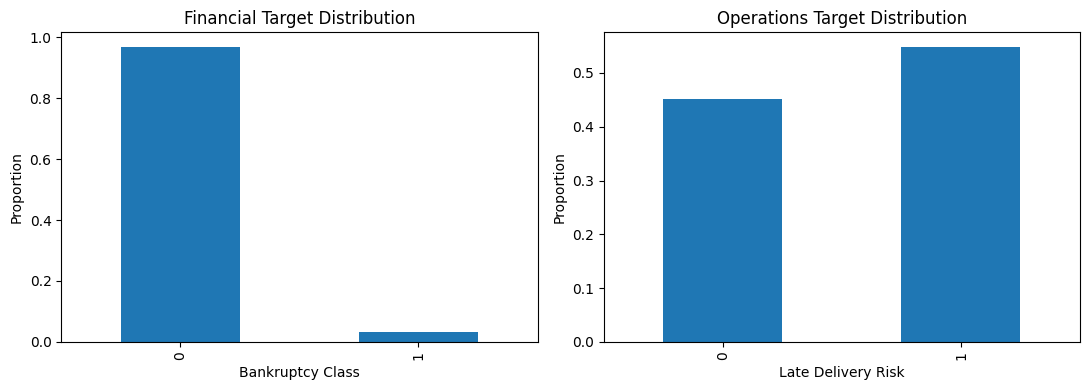

In [32]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

y_financial_train.value_counts(normalize=True).sort_index().plot(
    kind="bar",
    ax=axes[0]
)
axes[0].set_title("Financial Target Distribution")
axes[0].set_xlabel("Bankruptcy Class")
axes[0].set_ylabel("Proportion")

y_operations_train.value_counts(normalize=True).sort_index().plot(
    kind="bar",
    ax=axes[1]
)
axes[1].set_title("Operations Target Distribution")
axes[1].set_xlabel("Late Delivery Risk")
axes[1].set_ylabel("Proportion")

plt.tight_layout()
plt.show()

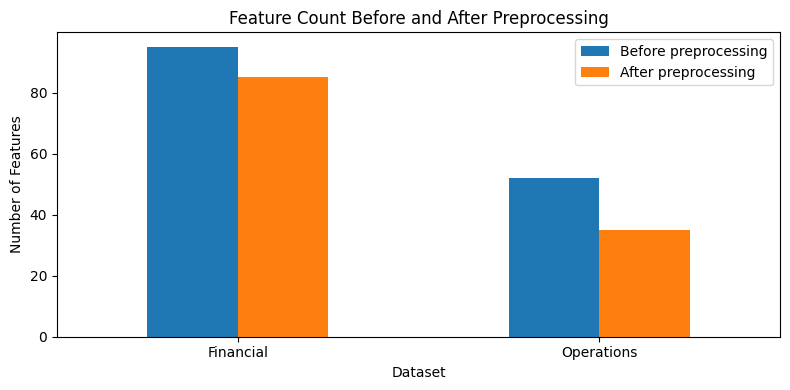

In [33]:
feature_comparison = pd.DataFrame({
    "Pipeline": ["Financial", "Operations"],
    "Before preprocessing": [
        financial_df.shape[1] - 1,
        operations_df.shape[1] - 1
    ],
    "After preprocessing": [
        X_financial_train_scaled.shape[1],
        X_operations_train_processed.shape[1]
    ]
})

feature_comparison.set_index("Pipeline").plot(
    kind="bar",
    figsize=(8, 4)
)

plt.title("Feature Count Before and After Preprocessing")
plt.xlabel("Dataset")
plt.ylabel("Number of Features")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [34]:
from google.colab import files

all_files = [
    "financial_X_train_processed.csv", "financial_X_test_processed.csv",
    "financial_y_train.csv", "financial_y_test.csv",
    "operations_X_train_processed.csv", "operations_X_test_processed.csv",
    "operations_y_train.csv", "operations_y_test.csv",
]
for fname in all_files:
    files.download(fname)

[colab stub] skipping browser download of financial_X_train_processed.csv (not running in Colab)
[colab stub] skipping browser download of financial_X_test_processed.csv (not running in Colab)
[colab stub] skipping browser download of financial_y_train.csv (not running in Colab)
[colab stub] skipping browser download of financial_y_test.csv (not running in Colab)
[colab stub] skipping browser download of operations_X_train_processed.csv (not running in Colab)
[colab stub] skipping browser download of operations_X_test_processed.csv (not running in Colab)
[colab stub] skipping browser download of operations_y_train.csv (not running in Colab)
[colab stub] skipping browser download of operations_y_test.csv (not running in Colab)


In [35]:
import joblib, os
out_dir = r"<AIT506_PROJECT_FOLDER>\CEROP_Live_Demo\models"
os.makedirs(out_dir, exist_ok=True)
joblib.dump(financial_scaler, os.path.join(out_dir, "cerop_financial_preprocessor.pkl"))
joblib.dump(operations_preprocessor, os.path.join(out_dir, "cerop_operations_preprocessor.pkl"))
print("Saved both preprocessors")

Saved both preprocessors
